In [1]:
# Load the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")

X_scaled = pd.read_csv("Customer_Features_Scaled.csv")
customer_features = pd.read_csv("Customer_Feature_Engineered.csv")
kmeans_results = pd.read_csv("KMeans_Customer_Segments.csv")

assert len(X_scaled) == len(customer_features) == len(kmeans_results)
assert X_scaled.isnull().sum().sum() == 0

print("Scaled data shape:", X_scaled.shape)
print("Customer data shape:", customer_features.shape)

Scaled data shape: (5044, 7)
Customer data shape: (5044, 13)


In [2]:
# Train the Hierarchical Clustering model
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

customer_features["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed!")
print("Number of clusters:",
      len(np.unique(hierarchical_labels)))

print("Silhouette Score:",
      round(silhouette_score(
          X_scaled,
          hierarchical_labels,
          sample_size=2000,
          random_state=42
      ), 4))

Hierarchical clustering completed!
Number of clusters: 4
Silhouette Score: 0.4865


,Cluster,Customer_Count,Percentage
0,0,3720,73.75
1,1,798,15.82
2,2,442,8.76
3,3,84,1.67


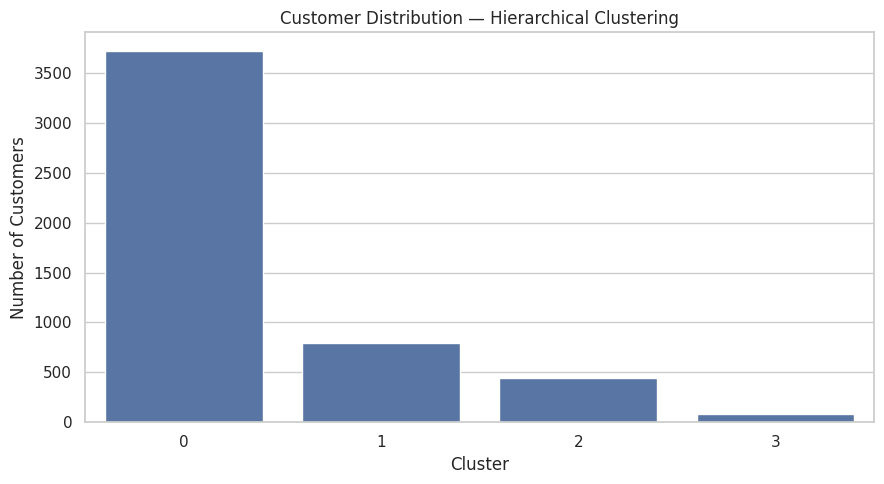

In [3]:
# Examine the cluster sizes
hierarchical_counts = (
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

hierarchical_distribution = pd.DataFrame({
    "Cluster": hierarchical_counts.index,
    "Customer_Count": hierarchical_counts.values,
    "Percentage": (
        hierarchical_counts.values
        / len(hierarchical_labels) * 100
    ).round(2)
})

display(hierarchical_distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=hierarchical_distribution,
    x="Cluster",
    y="Customer_Count"
)

plt.title("Customer Distribution — Hierarchical Clustering")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [4]:
# Analyze hierarchical cluster profiles
profile_columns = [
    "Total_Sales",
    "Total_Profit",
    "Total_Units",
    "Order_Count",
    "Product_Count",
    "Average_Sales_Per_Order",
    "Average_Units_Per_Order"
]

hierarchical_profile = (
    customer_features
    .groupby("Hierarchical_Cluster")[profile_columns]
    .mean()
    .round(2)
)

display(hierarchical_profile)

hierarchical_profile.to_csv(
    "Hierarchical_Cluster_Profiles.csv"
)

,Total_Sales,Total_Profit,Total_Units,Order_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order
Hierarchical_Cluster,,,,,,,
0,17.57,11.71,5.01,1.33,1.33,12.88,3.68
1,54.48,36.01,15.10,3.35,3.32,16.24,4.49
2,45.30,29.81,11.95,1.29,1.29,35.36,9.31
3,153.84,94.84,32.06,4.13,3.37,46.11,8.40


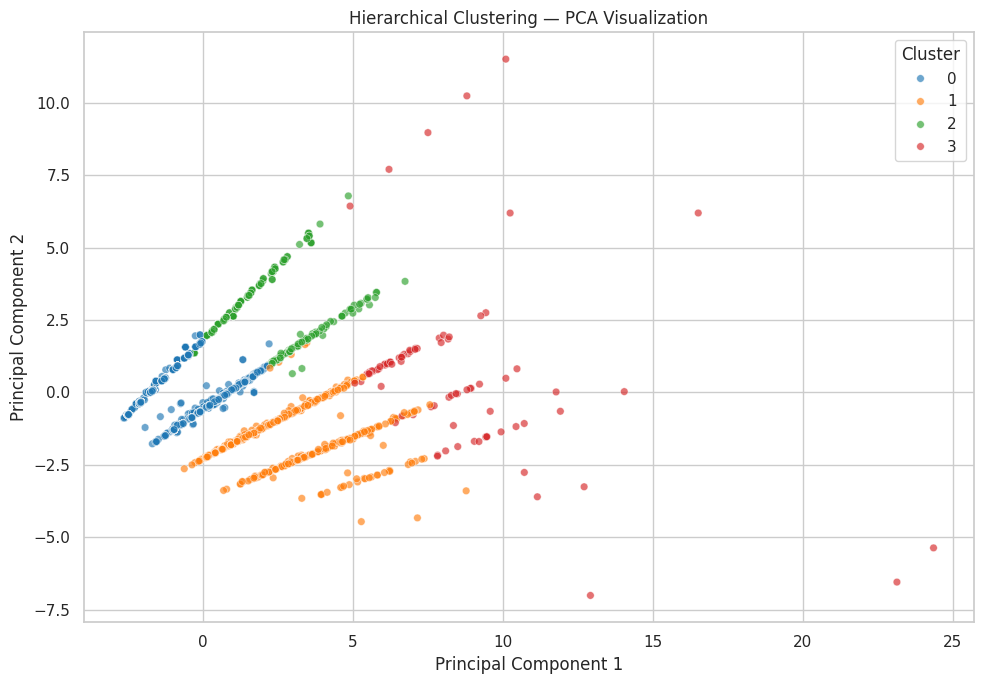

In [5]:
# Visualize the hierarchical clusters
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": hierarchical_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=30
)

plt.title("Hierarchical Clustering — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [6]:
# Compare K-Means and Hierarchical Clustering
kmeans_labels = kmeans_results["Cluster"].to_numpy()

comparison = pd.DataFrame({
    "Model": [
        "K-Means",
        "Hierarchical Clustering"
    ],
    "Clusters": [
        len(np.unique(kmeans_labels)),
        len(np.unique(hierarchical_labels))
    ],
    "Silhouette_Score": [
        silhouette_score(
            X_scaled, kmeans_labels,
            sample_size=2000, random_state=42
        ),
        silhouette_score(
            X_scaled, hierarchical_labels,
            sample_size=2000, random_state=42
        )
    ]
})

display(comparison.round(4))

ari = adjusted_rand_score(
    kmeans_labels,
    hierarchical_labels
)

print("Adjusted Rand Index:", round(ari, 4))

,Model,Clusters,Silhouette_Score
0,K-Means,4,0.4639
1,Hierarchical Clustering,4,0.4865


Adjusted Rand Index: 0.3412


In [7]:
# Save the results
customer_features["KMeans_Cluster"] = kmeans_labels
customer_features["Hierarchical_Cluster"] = hierarchical_labels

customer_features.to_csv(
    "Customer_Segmentation_Comparison.csv",
    index=False
)

comparison.to_csv(
    "Clustering_Model_Comparison.csv",
    index=False
)

print("Step 6 completed.")
print("Saved Customer_Segmentation_Comparison.csv")
print("Saved Clustering_Model_Comparison.csv")

Step 6 completed.
Saved Customer_Segmentation_Comparison.csv
Saved Clustering_Model_Comparison.csv
